# 1. Setup

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")

CLASSES = ["call", "dislike", "fist", "four", "like"]
PROB_COLS = [f"prob_{c}" for c in CLASSES]
N_CLUSTERS = 5

files = {
    "original": "/Users/Jakub/Desktop/AI-VIS/phase1-Ai/split_preprocess-train/base results and setup/test_set_merged.csv",
    "flipped_upside_down": "/Users/Jakub/Downloads/test_results_flipped_upside_down.csv",
    "black_and_white": "/Users/Jakub/Downloads/test_results_black_and_white.csv",
    "brightness_raised": "/Users/Jakub/Downloads/test_results_brightness_raised.csv",
}

data = {}
for name, path in files.items():
    d = pd.read_csv(path)
    d["age_bin"] = pd.qcut(d["age"], q=4)
    data[name] = d

# 2. Behavioral clustering: group images by their output probability vector, not input features

In [2]:
def add_clusters(df):
    km = KMeans(n_clusters=N_CLUSTERS, random_state=0, n_init=10)
    df["cluster"] = km.fit_predict(df[PROB_COLS].values)
    return df

for name, d in data.items():
    data[name] = add_clusters(d)

# 3. Clustermap of probability vectors per condition, annotated by true label and correctness

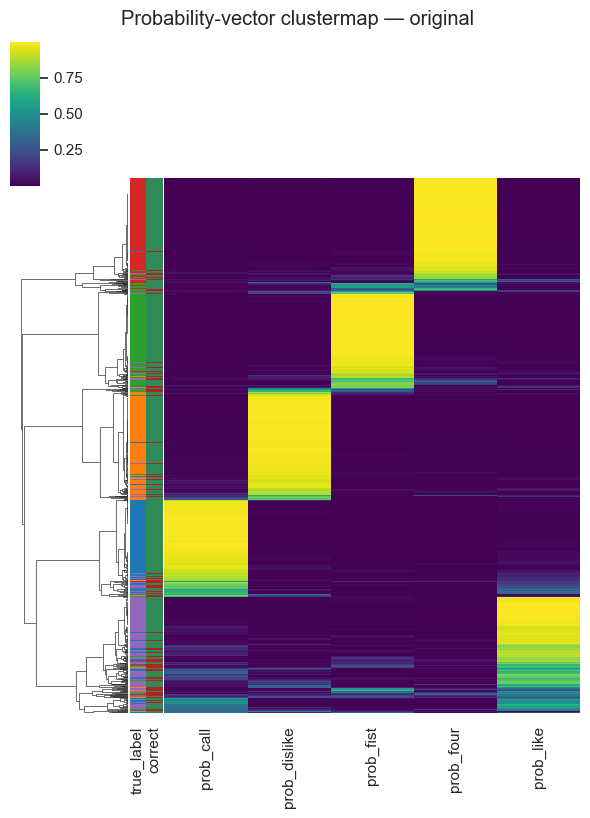

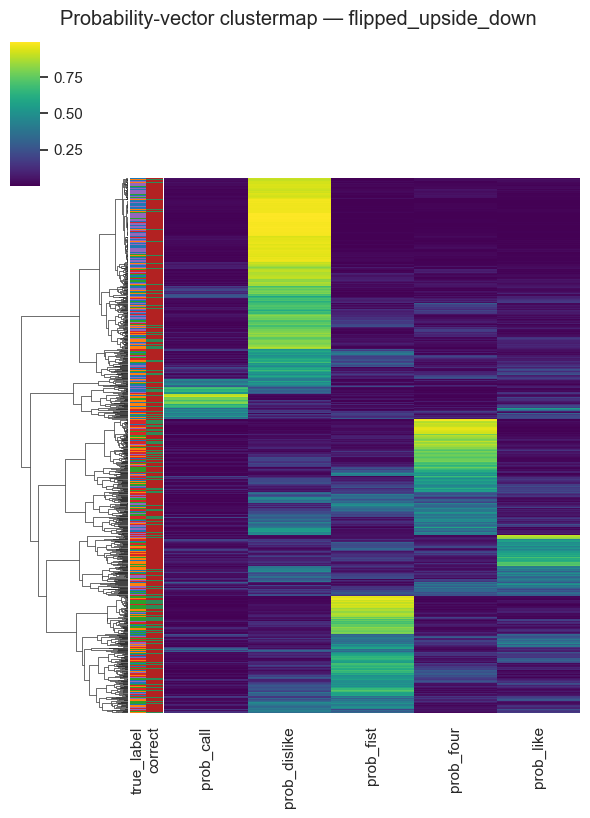

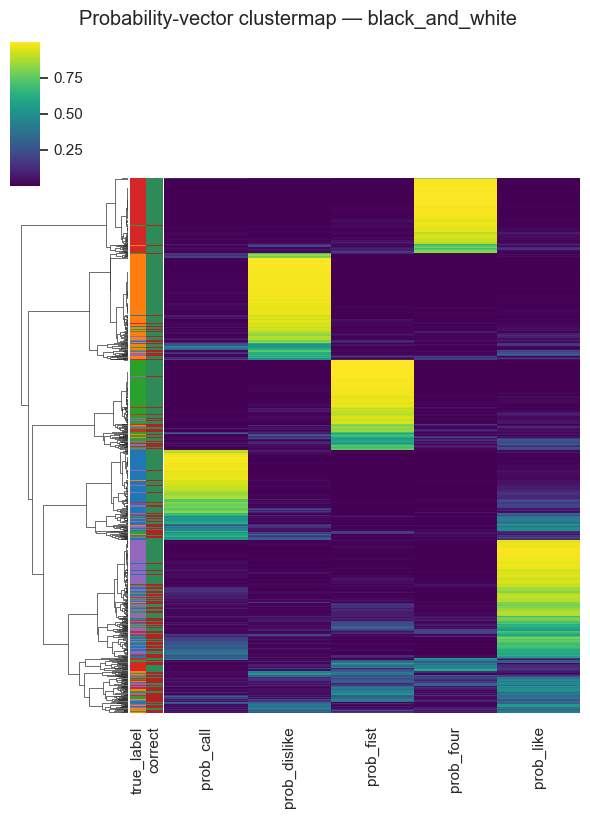

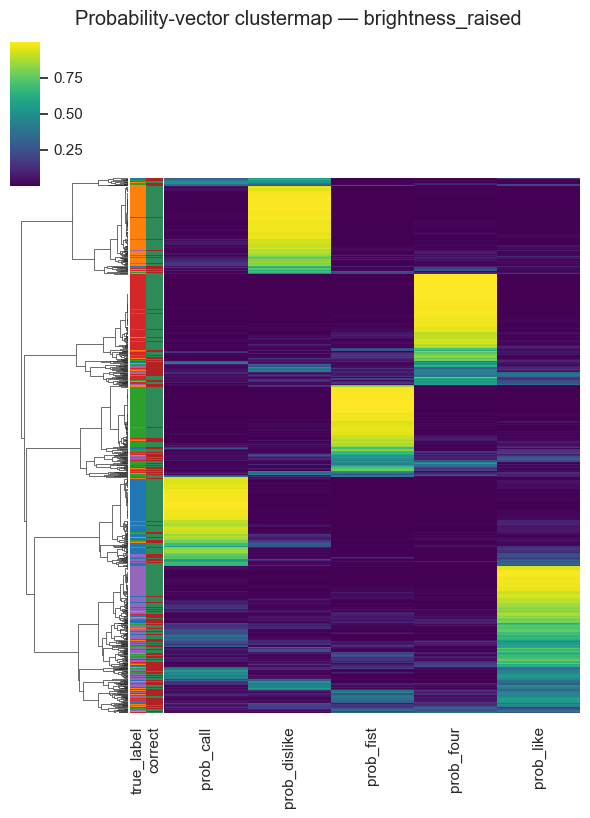

In [3]:
def plot_clustermap(df, name):
    true_palette = dict(zip(CLASSES, sns.color_palette("tab10", len(CLASSES))))
    correct_palette = {True: "seagreen", False: "firebrick"}

    row_colors = pd.DataFrame({
        "true_label": df["true_label"].map(true_palette),
        "correct": df["correct"].map(correct_palette),
    }, index=df.index)

    g = sns.clustermap(
        df[PROB_COLS], row_colors=row_colors, col_cluster=False,
        yticklabels=False, cmap="viridis", figsize=(6, 8),
    )
    g.fig.suptitle(f"Probability-vector clustermap — {name}", y=1.02)
    plt.show()

for name, d in data.items():
    plot_clustermap(d, name)

# 4. Cluster composition: what each behavioral cluster actually contains

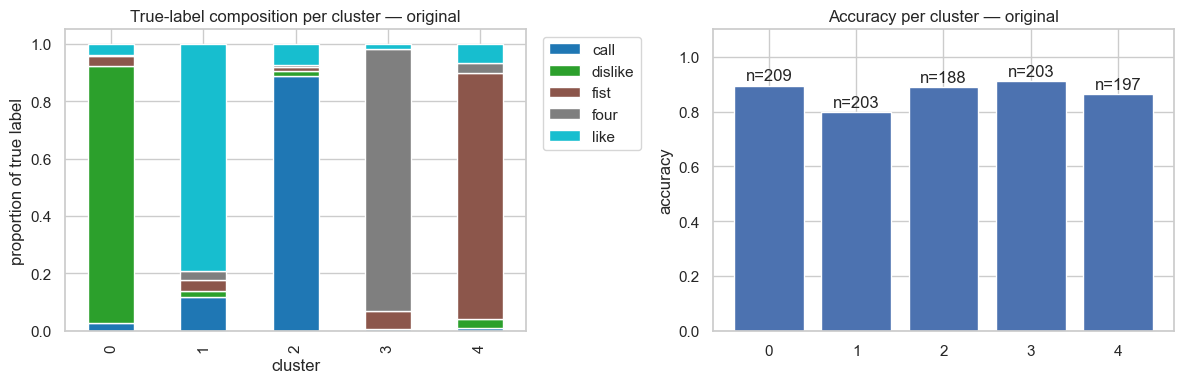

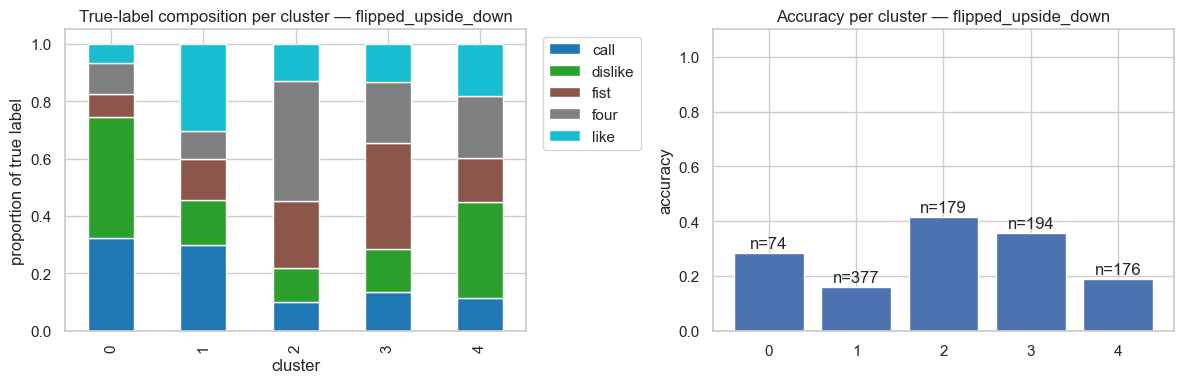

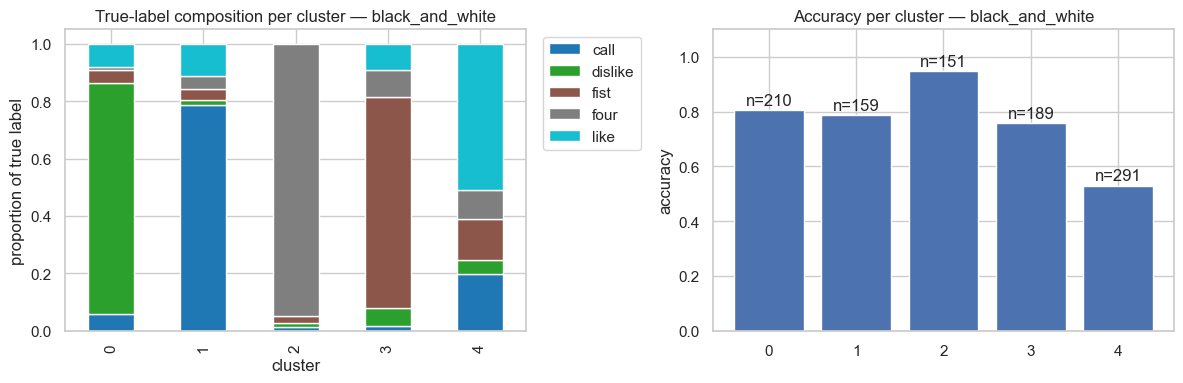

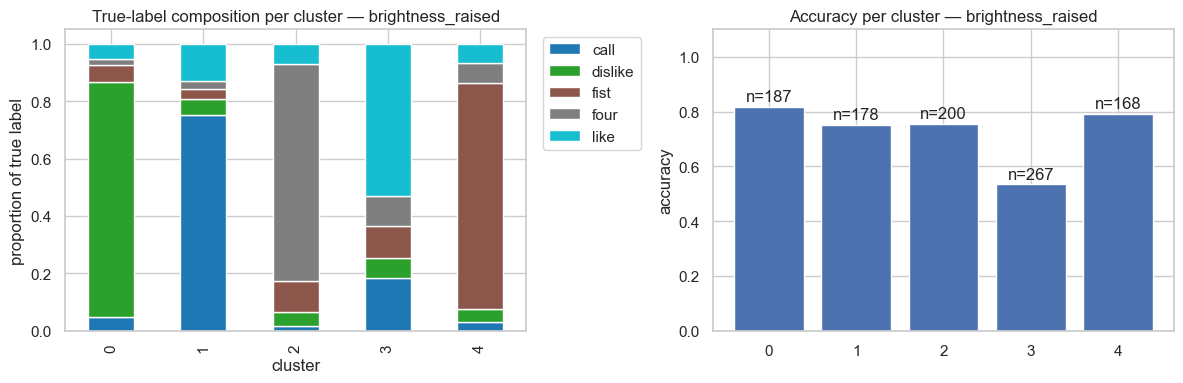

In [4]:
def plot_cluster_composition(df, name):
    comp = pd.crosstab(df["cluster"], df["true_label"], normalize="index")[CLASSES]
    acc = df.groupby("cluster")["correct"].mean()
    sizes = df.groupby("cluster").size()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    comp.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab10")
    axes[0].set_ylabel("proportion of true label")
    axes[0].set_title(f"True-label composition per cluster — {name}")
    axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left")

    axes[1].bar(acc.index.astype(str), acc.values)
    for i, (a, s) in enumerate(zip(acc.values, sizes.values)):
        axes[1].text(i, a + 0.02, f"n={s}", ha="center")
    axes[1].set_ylim(0, 1.1)
    axes[1].set_ylabel("accuracy")
    axes[1].set_title(f"Accuracy per cluster — {name}")
    plt.tight_layout()
    plt.show()

for name, d in data.items():
    plot_cluster_composition(d, name)

# 5. PCA projection of probability vectors, colored by cluster and by correctness

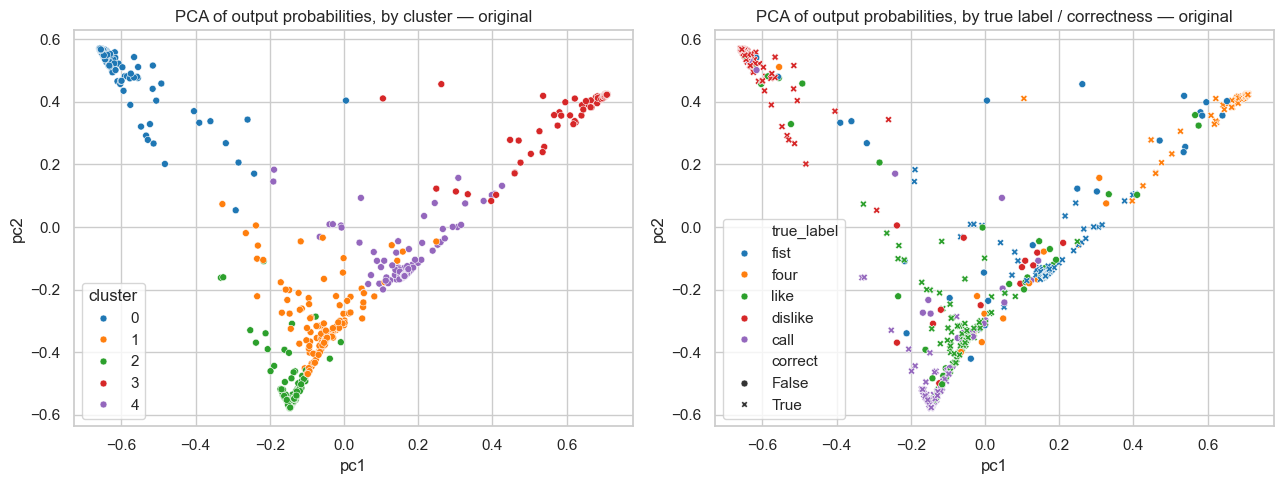

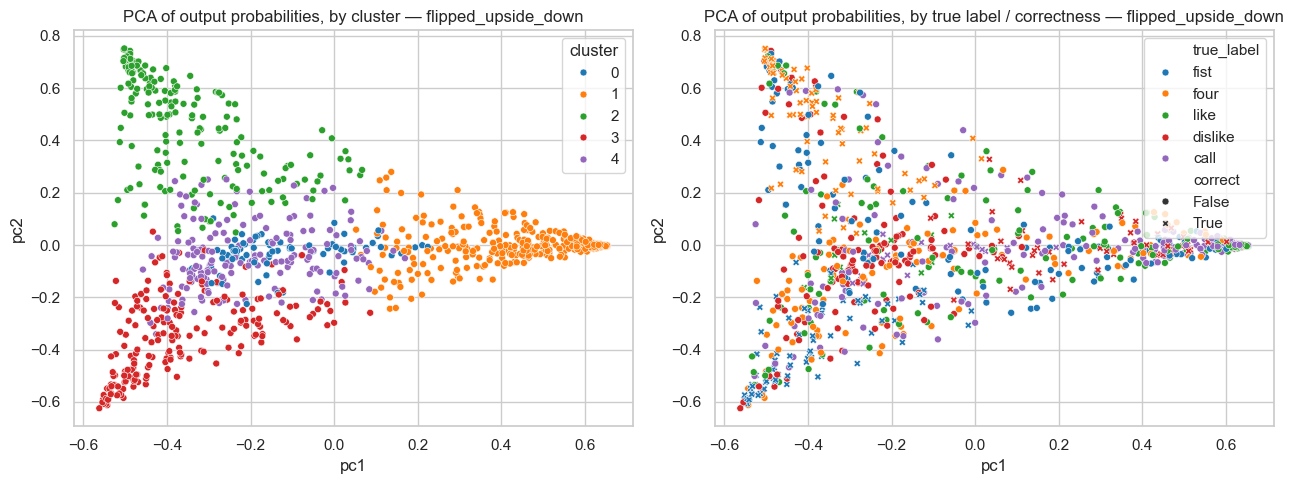

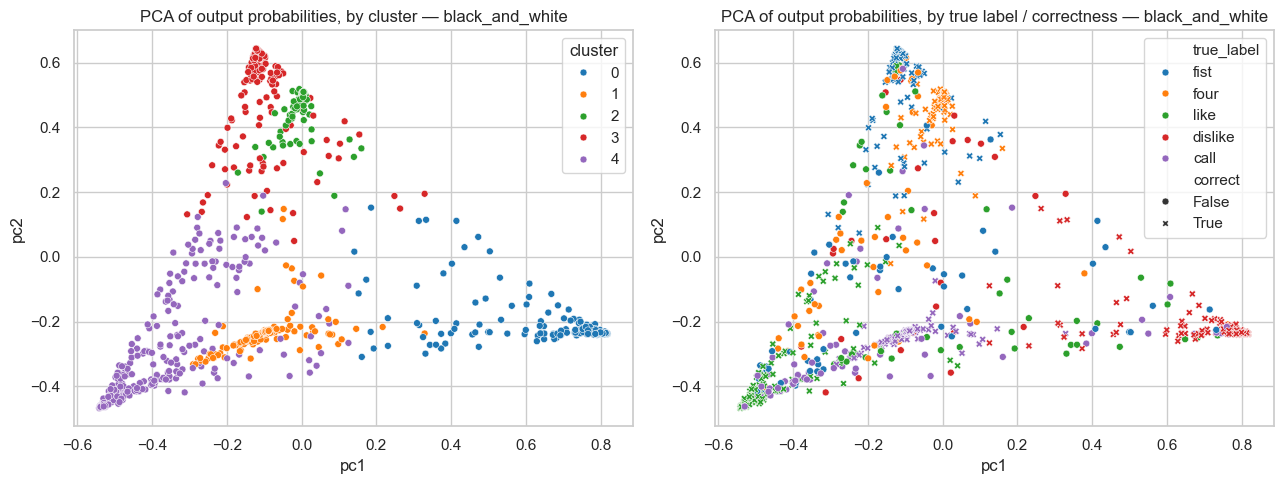

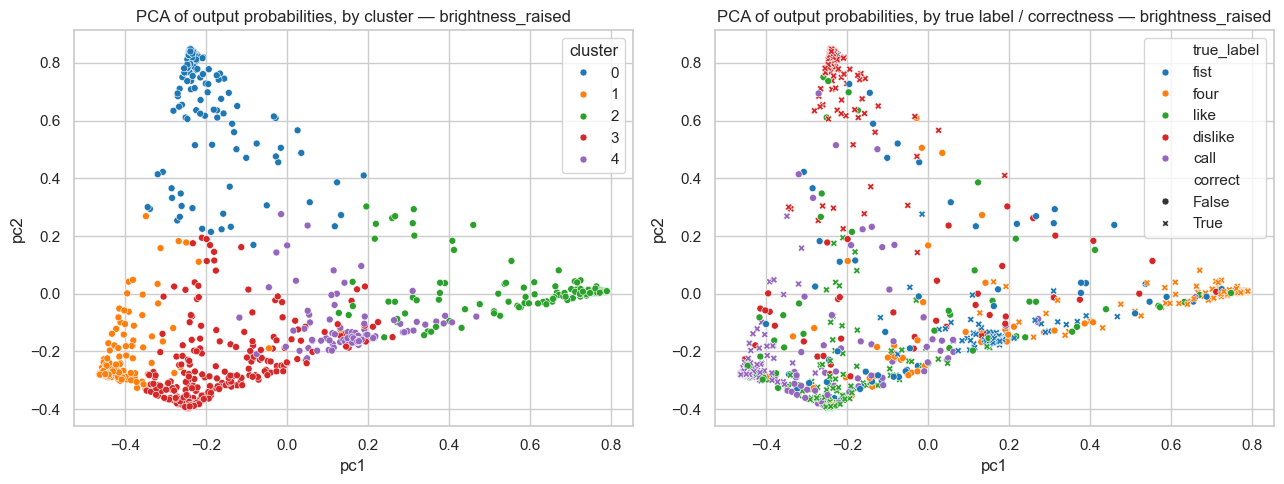

In [5]:
def plot_pca(df, name):
    pcs = PCA(n_components=2, random_state=0).fit_transform(df[PROB_COLS].values)
    df["pc1"], df["pc2"] = pcs[:, 0], pcs[:, 1]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    sns.scatterplot(data=df, x="pc1", y="pc2", hue="cluster", palette="tab10", ax=axes[0], s=25)
    axes[0].set_title(f"PCA of output probabilities, by cluster — {name}")

    sns.scatterplot(data=df, x="pc1", y="pc2", hue="true_label", style="correct",
                     palette="tab10", ax=axes[1], s=25)
    axes[1].set_title(f"PCA of output probabilities, by true label / correctness — {name}")
    plt.tight_layout()
    plt.show()

for name, d in data.items():
    plot_pca(d, name)

# 6. Metadata relationships per condition

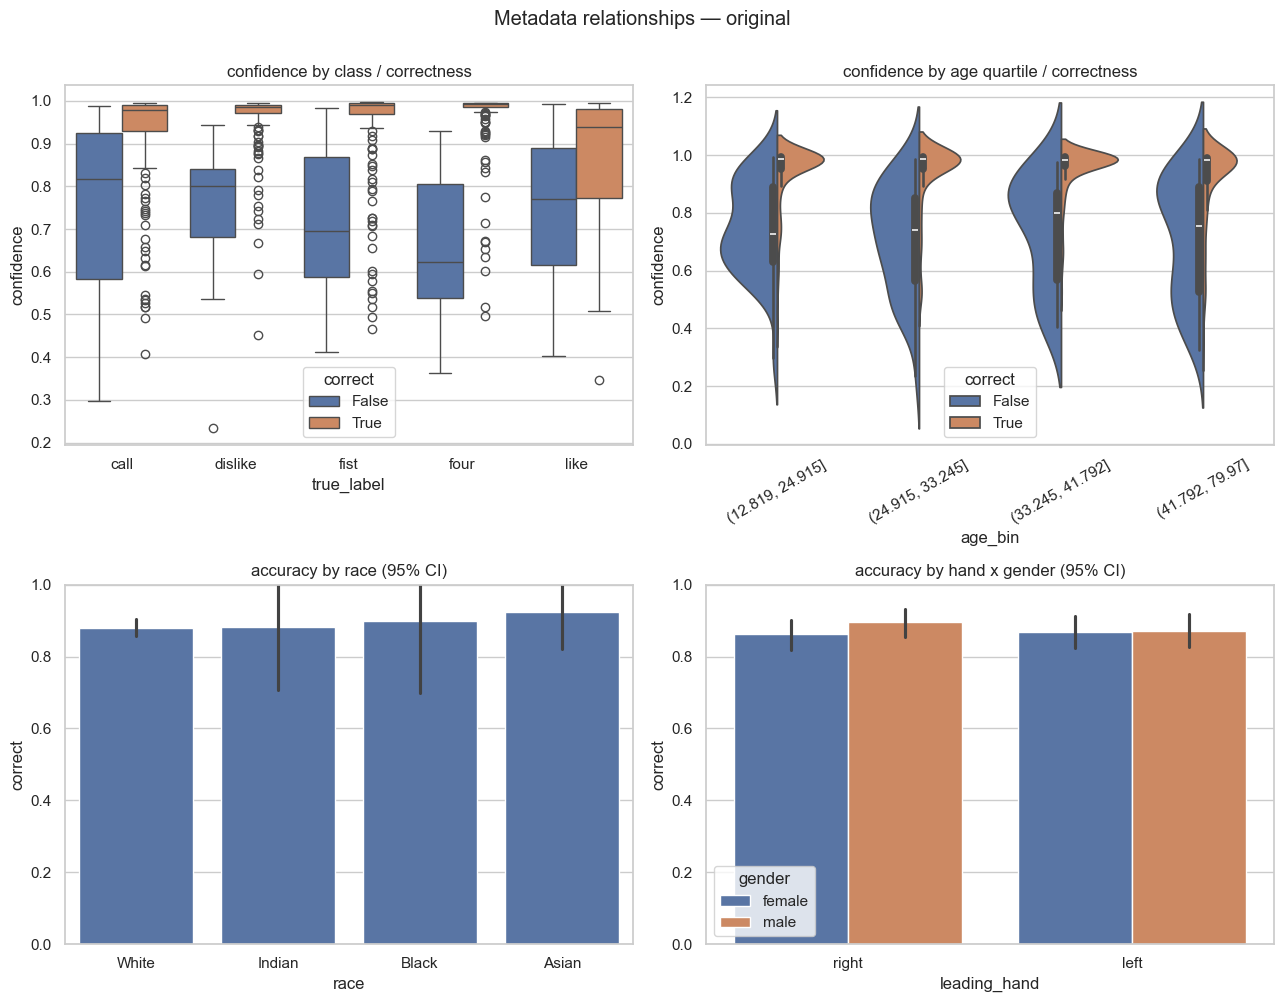

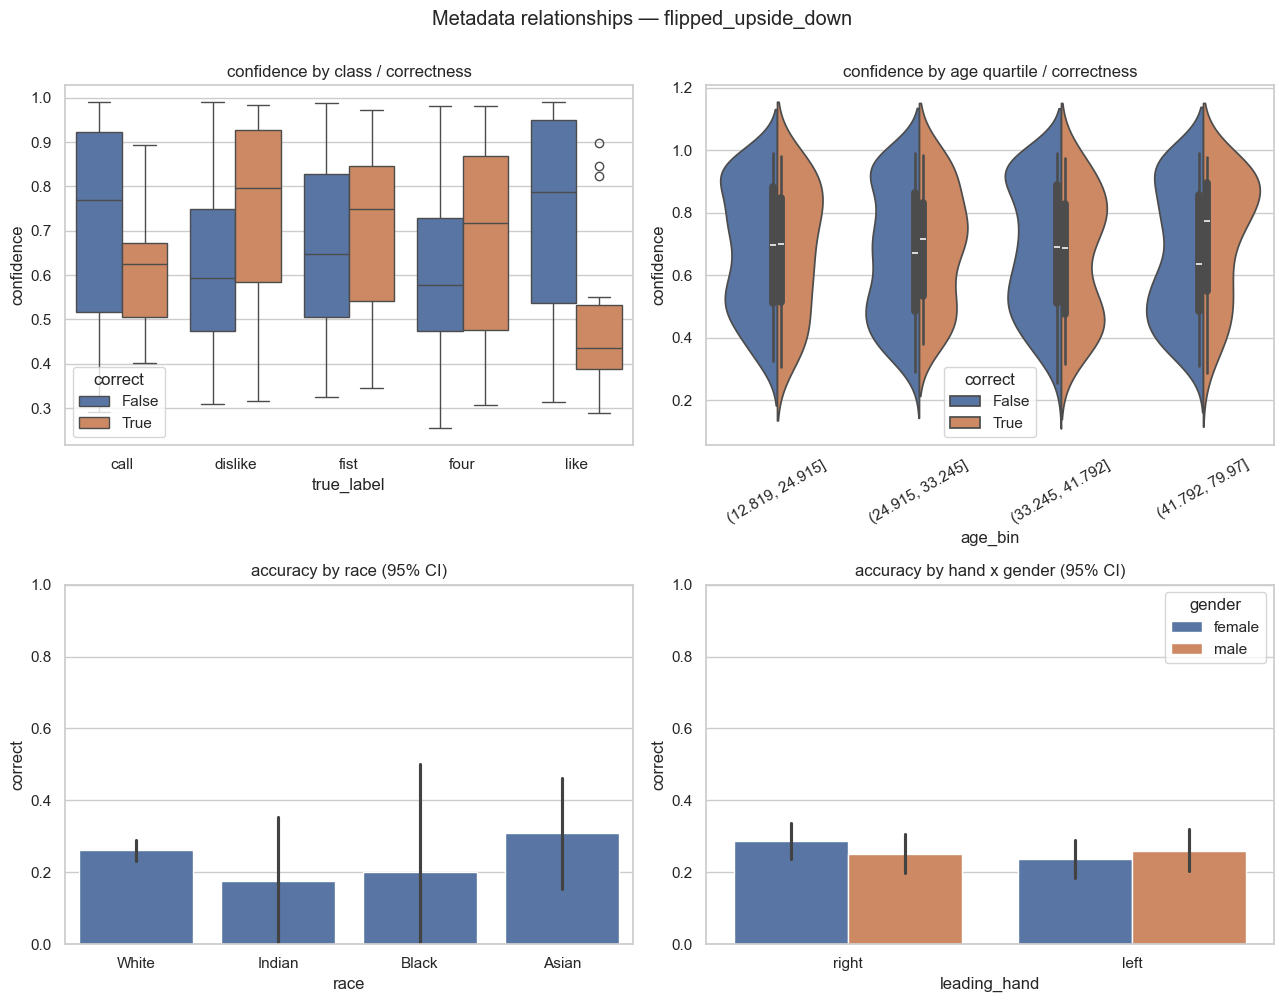

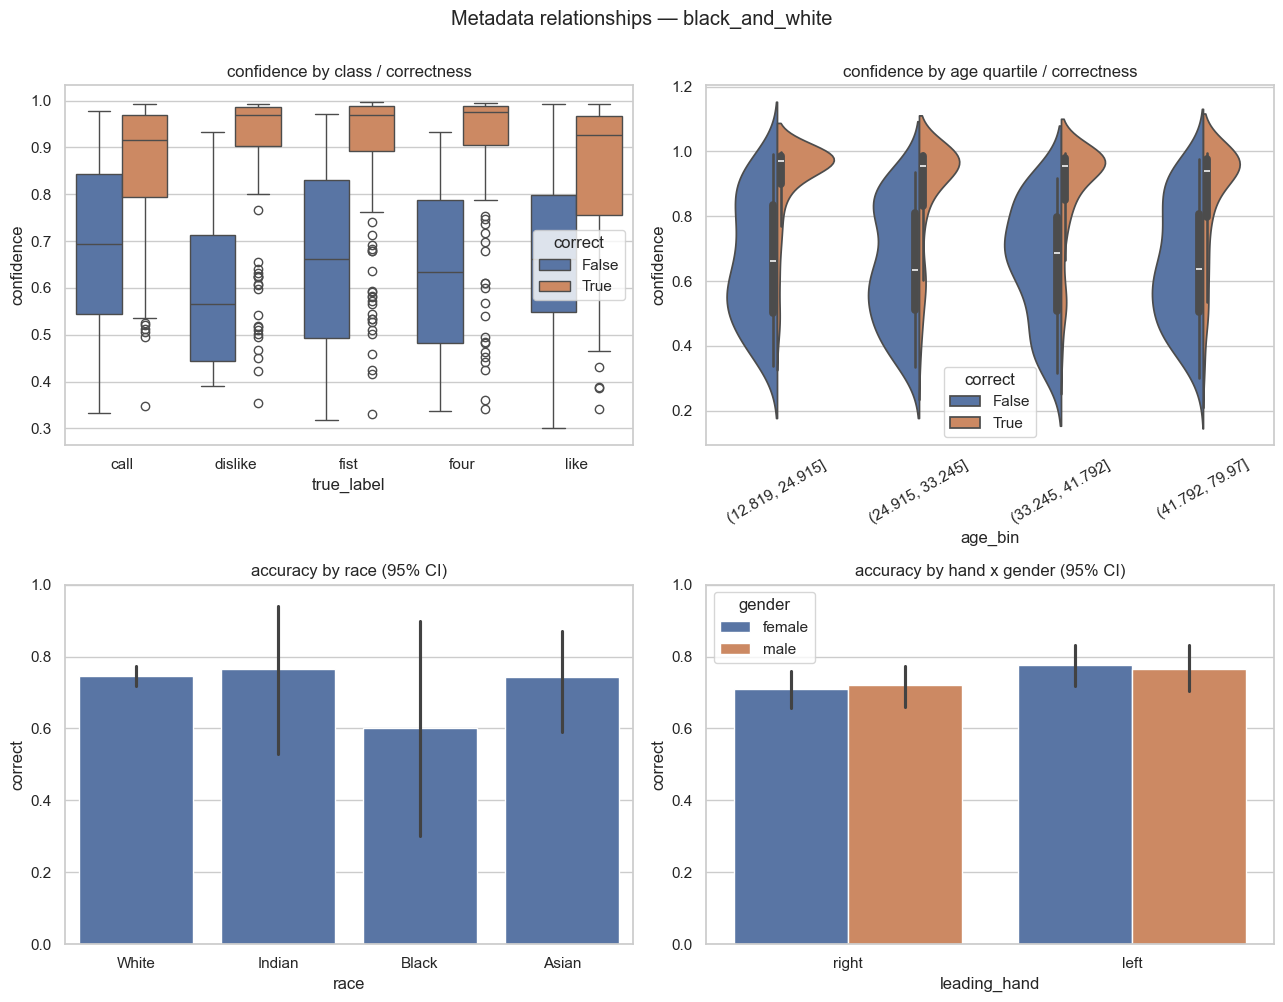

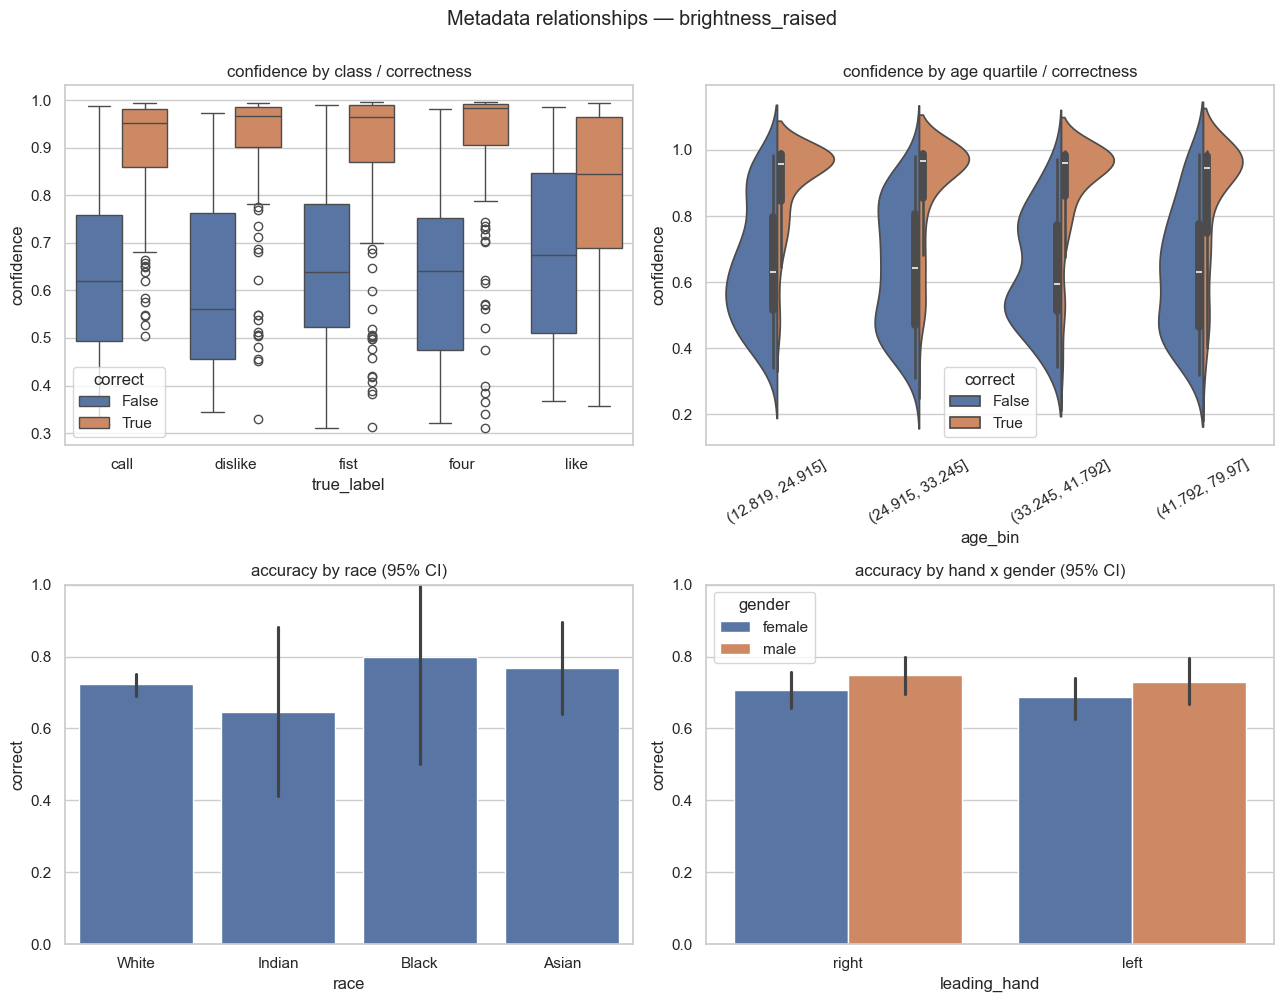

In [6]:
def plot_metadata(df, name):
    fig, axes = plt.subplots(2, 2, figsize=(13, 10))

    sns.boxplot(data=df, x="true_label", y="confidence", hue="correct", order=CLASSES, ax=axes[0, 0])
    axes[0, 0].set_title("confidence by class / correctness")

    sns.violinplot(data=df, x="age_bin", y="confidence", hue="correct", split=True, ax=axes[0, 1])
    axes[0, 1].set_title("confidence by age quartile / correctness")
    axes[0, 1].tick_params(axis="x", rotation=30)

    sns.barplot(data=df, x="race", y="correct", ax=axes[1, 0], estimator=np.mean, errorbar=("ci", 95))
    axes[1, 0].set_title("accuracy by race (95% CI)")
    axes[1, 0].set_ylim(0, 1)

    sns.barplot(data=df, x="leading_hand", y="correct", hue="gender", ax=axes[1, 1], errorbar=("ci", 95))
    axes[1, 1].set_title("accuracy by hand x gender (95% CI)")
    axes[1, 1].set_ylim(0, 1)

    fig.suptitle(f"Metadata relationships — {name}", y=1.0)
    plt.tight_layout()
    plt.show()

for name, d in data.items():
    plot_metadata(d, name)

# 7. Cluster composition by metadata (does a behavioral cluster concentrate in a demographic group?)

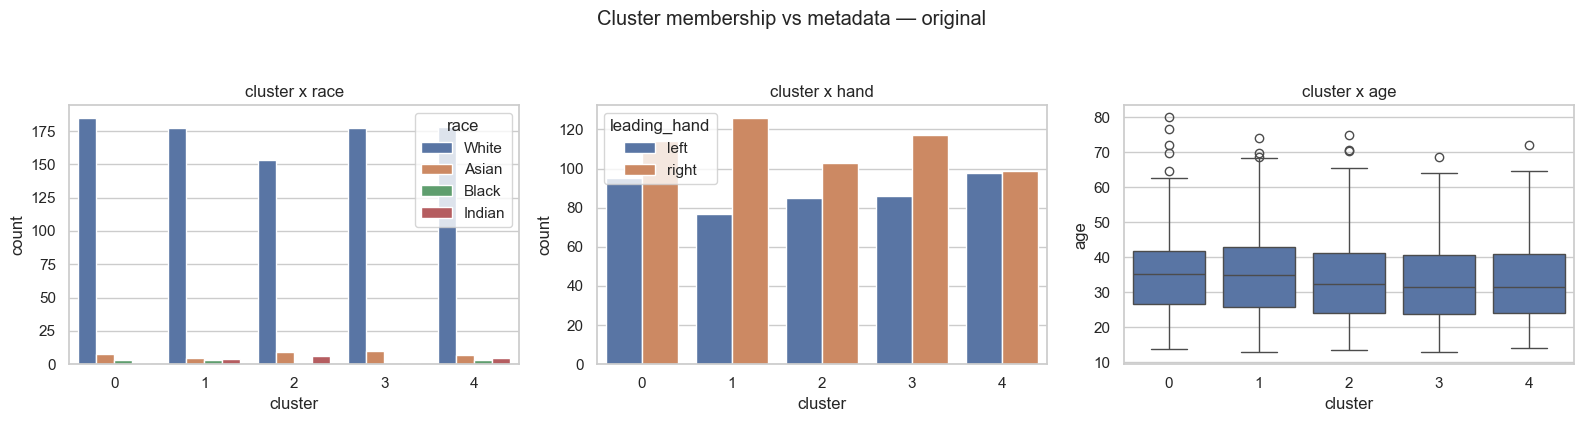

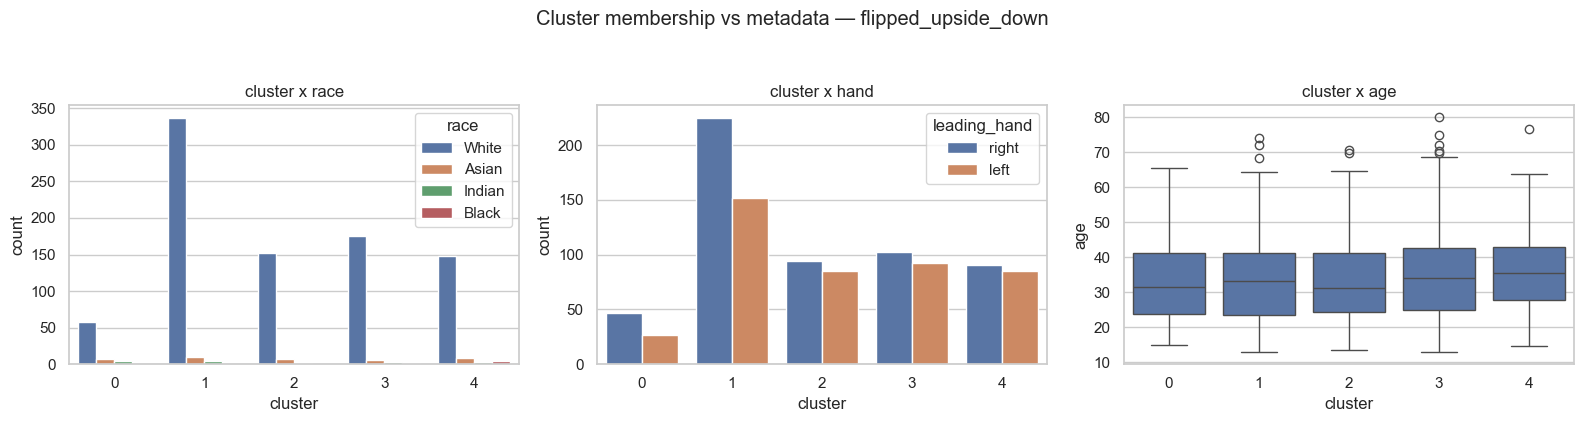

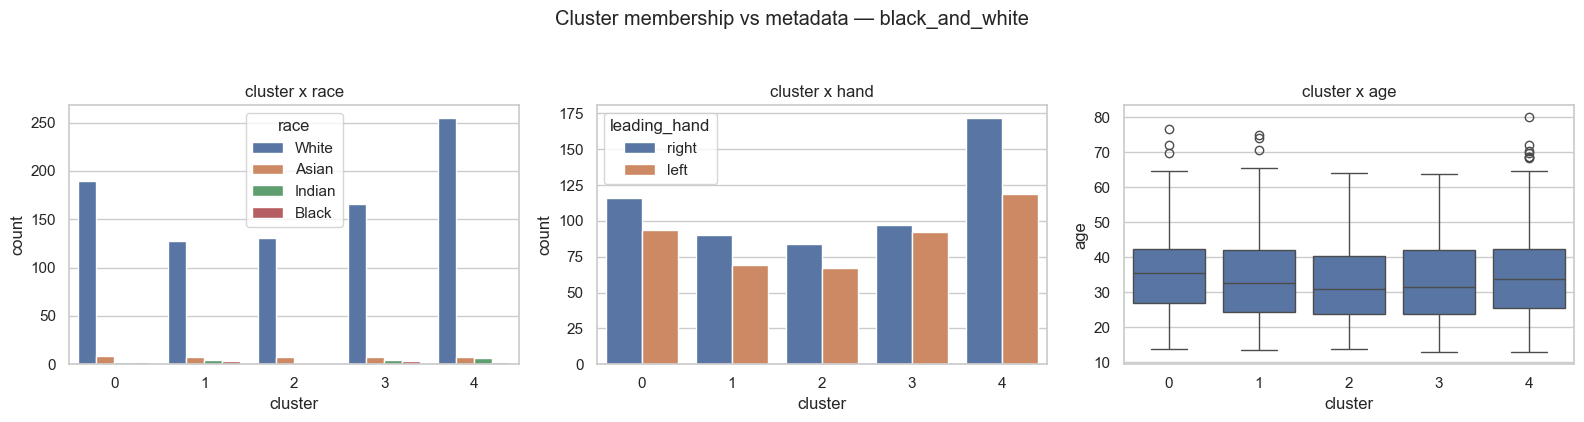

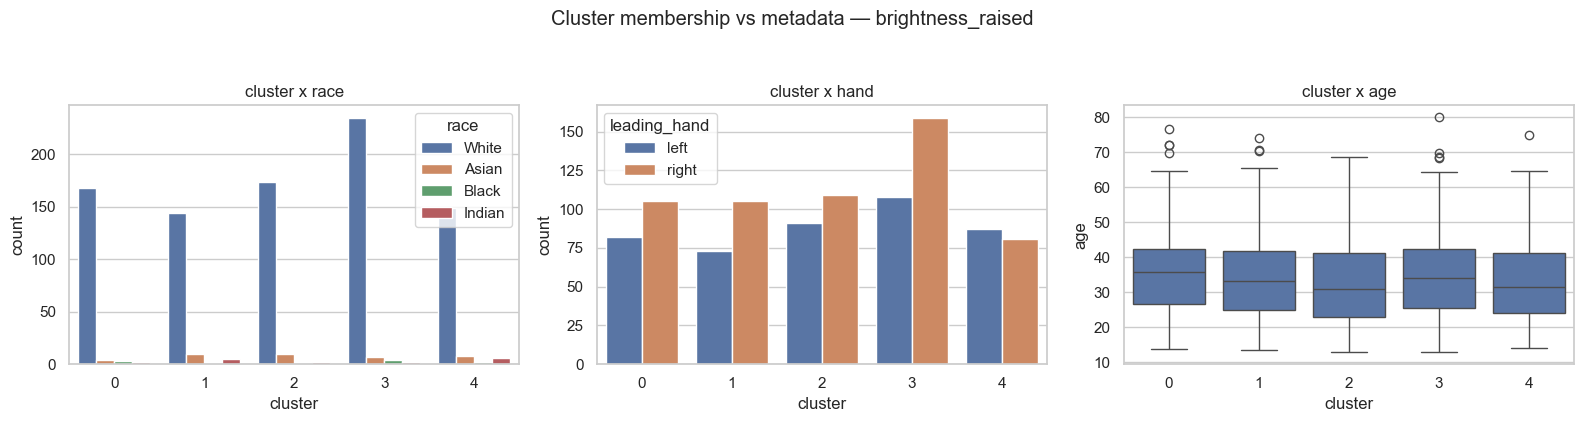

In [7]:
def plot_cluster_by_metadata(df, name):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    sns.countplot(data=df, x="cluster", hue="race", ax=axes[0])
    axes[0].set_title("cluster x race")

    sns.countplot(data=df, x="cluster", hue="leading_hand", ax=axes[1])
    axes[1].set_title("cluster x hand")

    sns.boxplot(data=df, x="cluster", y="age", ax=axes[2])
    axes[2].set_title("cluster x age")

    fig.suptitle(f"Cluster membership vs metadata — {name}", y=1.05)
    plt.tight_layout()
    plt.show()

for name, d in data.items():
    plot_cluster_by_metadata(d, name)